# 02 — Amélioration : transfer learning EfficientNetB0

Ce notebook améliore la baseline du notebook 01 en réutilisant un réseau **pré-entraîné sur ImageNet**
(1,3 million d'images, 1 000 classes). Ses couches ont déjà appris des contours, des textures et des formes
génériques ; il reste à les adapter aux 27 catégories Rakuten.

L'entraînement se fait en deux étapes, chacune sauvegardée et évaluée séparément :

1. **Feature extraction** : le backbone est gelé, seule la nouvelle tête apprend
   (`feature_extraction_best.keras`) ;
2. **Fine-tuning** : les 30 dernières couches du backbone sont dégelées et ajustées avec un taux
   d'apprentissage très faible (`best_model.keras`).

Le protocole (données, split, augmentation, perte, callbacks) est identique à celui du notebook 01.
EfficientNet Keras intègre sa propre mise à l'échelle et attend des pixels dans `[0, 255]`.


In [1]:
from pathlib import Path
import json
import os
import random

import certifi
import numpy as np
import pandas as pd

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Python installé depuis python.org sur macOS ne référence pas toujours le trousseau
# système. On fournit à urllib/Keras un bundle CA explicite sans désactiver SSL.
os.environ["SSL_CERT_FILE"] = certifi.where()
os.environ["REQUESTS_CA_BUNDLE"] = certifi.where()

def find_project_root() -> Path:
    """Permet d'exécuter le notebook depuis sa racine ou son propre dossier."""
    candidates = [Path.cwd(), *Path.cwd().parents]
    for candidate in candidates:
        if (candidate / "data" / "raw_x.csv").exists() and (candidate / "images").exists():
            return candidate
    raise FileNotFoundError("Racine du projet introuvable (data/raw_x.csv et images/ attendus).")

ROOT = find_project_root()
DATA_DIR = ROOT / "data"
IMAGE_DIR = ROOT / "images" / "image_train"
ARTIFACTS_DIR = ROOT / "artifacts" / "image_classification"
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("KERAS_HOME", str(ARTIFACTS_DIR / ".keras"))

print("Racine :", ROOT)
print("Artefacts :", ARTIFACTS_DIR)
print("Certificats SSL :", os.environ["SSL_CERT_FILE"])


Racine : /Users/wolfidy7/projects/sep25_alt2_iia_rakuten_2
Artefacts : /Users/wolfidy7/projects/sep25_alt2_iia_rakuten_2/artifacts/image_classification
Certificats SSL : /Users/wolfidy7/projects/sep25_alt2_iia_rakuten_2/.conda/rakuten-metal/lib/python3.10/site-packages/certifi/cacert.pem


In [2]:
import tensorflow as tf

tf.keras.utils.set_random_seed(SEED)

TARGET_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

with open(ARTIFACTS_DIR / "class_mapping.json", encoding="utf-8") as handle:
    class_mapping = json.load(handle)

index_to_code = [int(value) for value in class_mapping["index_to_code"]]
code_to_index = {code: index for index, code in enumerate(index_to_code)}
NUM_CLASSES = len(index_to_code)

manifest = pd.read_csv(ARTIFACTS_DIR / "image_manifest.csv")
manifest["class_index"] = manifest["prdtypecode"].map(code_to_index)
assert manifest["class_index"].notna().all()

def decode_resize(path, label, weight):
    image = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize_with_pad(image, *TARGET_SIZE, antialias=True)
    image = tf.cast(image, tf.float32)  # Pixels dans [0, 255] : chaque modèle gère sa mise à l'échelle.
    return image, tf.cast(label, tf.int32), tf.cast(weight, tf.float32)

def make_dataset(frame, training=False, transform=None, weighted=False):
    paths = frame["image_path"].astype(str).to_numpy()
    labels = frame["class_index"].astype("int32").to_numpy()
    weights = frame["sample_weight"].astype("float32").to_numpy()
    ds = tf.data.Dataset.from_tensor_slices((paths, labels, weights))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(decode_resize, num_parallel_calls=AUTOTUNE)
    if transform is not None:
        ds = ds.map(transform, num_parallel_calls=AUTOTUNE)
    if not weighted:
        ds = ds.map(lambda x, y, w: (x, y), num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

train_df = manifest.query("split == 'train'").copy()
val_df = manifest.query("split == 'validation'").copy()
print(f"Train={len(train_df):,} | Validation={len(val_df):,} | Classes={NUM_CLASSES}")


Train=65,900 | Validation=16,475 | Classes=27


In [3]:
import time

import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, classification_report, f1_score, top_k_accuracy_score
from tensorflow import keras
from tensorflow.keras import layers

def build_augmentation():
    """Augmentation identique pour tous les modèles : seule l'architecture change d'un run à l'autre."""
    return keras.Sequential(
        [
            layers.RandomRotation(0.03, fill_mode="reflect", seed=SEED),
            layers.RandomZoom(0.10, fill_mode="reflect", seed=SEED),
            layers.RandomContrast(0.10, seed=SEED),
        ],
        name="augmentation",
    )

def compile_model(model, learning_rate):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=[
            keras.metrics.SparseCategoricalAccuracy(name="accuracy"),
            keras.metrics.SparseTopKCategoricalAccuracy(k=3, name="top3_accuracy"),
        ],
    )

class EpochTimer(keras.callbacks.Callback):
    """Ajoute la durée de chaque époque au journal CSV."""

    def on_epoch_begin(self, epoch, logs=None):
        self._start = time.perf_counter()

    def on_epoch_end(self, epoch, logs=None):
        if logs is not None:
            logs["epoch_time_s"] = time.perf_counter() - self._start

def callbacks_for(run_dir, checkpoint_name, patience, append):
    run_dir.mkdir(parents=True, exist_ok=True)
    return [
        EpochTimer(),  # Doit précéder CSVLogger pour que la durée soit journalisée.
        keras.callbacks.ModelCheckpoint(
            run_dir / checkpoint_name, monitor="val_loss", save_best_only=True
        ),
        keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=patience, restore_best_weights=True
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.2, patience=2, min_lr=1e-7
        ),
        keras.callbacks.CSVLogger(run_dir / "training_log.csv", append=append),
    ]

def count_params(model):
    trainable = int(sum(np.prod(weight.shape) for weight in model.trainable_weights))
    return {"params_total": int(model.count_params()), "params_trainable": trainable}

def save_run_summary(run_dir, **values):
    """Fusionne les informations du run dans run_summary.json, relu par le notebook 03."""
    path = run_dir / "run_summary.json"
    summary = json.loads(path.read_text(encoding="utf-8")) if path.exists() else {}
    summary.update(values)
    path.write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8")
    return summary

def evaluate_on_validation(model, dataset, frame):
    probabilities = model.predict(dataset, verbose=1)
    y_true = frame["class_index"].to_numpy()
    y_pred = probabilities.argmax(axis=1)
    metrics = {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "top3_accuracy": float(top_k_accuracy_score(
            y_true, probabilities, k=3, labels=np.arange(NUM_CLASSES)
        )),
        "f1_weighted": float(f1_score(y_true, y_pred, average="weighted")),
        "f1_macro": float(f1_score(y_true, y_pred, average="macro")),
    }
    return metrics, y_true, y_pred

def plot_history(log_path, title, phase_boundary=None):
    log = pd.read_csv(log_path)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for ax, metric in zip(axes, ["loss", "accuracy"]):
        ax.plot(log["epoch"] + 1, log[metric], marker="o", label="train")
        ax.plot(log["epoch"] + 1, log[f"val_{metric}"], marker="o", label="validation")
        if phase_boundary is not None:
            ax.axvline(phase_boundary + 0.5, color="grey", linestyle="--", label="début du fine-tuning")
        ax.set_xlabel("Époque")
        ax.set_title(metric)
        ax.grid(alpha=0.3)
        ax.legend()
    fig.suptitle(title)
    plt.tight_layout(rect=(0, 0, 1, 1 - 0.6 / fig.get_figheight()))
    plt.show()


## Architecture

- **Backbone** : EfficientNetB0 sans sa tête ImageNet (`include_top=False`), soit environ 4 millions de
  paramètres. Sa sortie est une carte 7 × 7 × 1280.
- **Tête** : identique à celle du CNN du notebook 01 (pooling global, dropout 0,30, softmax à 27 classes).
- Le backbone est appelé avec `training=False` : ses couches BatchNorm restent en mode inférence, même
  une fois dégelées, pour ne pas dégrader leurs statistiques ImageNet avec des lots de 32 images.


In [4]:
def build_efficientnet():
    inputs = keras.Input(shape=(*TARGET_SIZE, 3), name="image")
    x = build_augmentation()(inputs)
    local_weights = ARTIFACTS_DIR / ".keras" / "models" / "efficientnetb0_notop.h5"
    weights = str(local_weights) if local_weights.exists() else "imagenet"
    print("Poids EfficientNet :", weights)
    backbone = keras.applications.EfficientNetB0(
        include_top=False,
        weights=weights,
        input_shape=(*TARGET_SIZE, 3),
    )
    backbone.trainable = False
    x = backbone(x, training=False)
    x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
    x = layers.Dropout(0.30, seed=SEED)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="prdtypecode")(x)
    return keras.Model(inputs, outputs, name="efficientnet_transfer"), backbone

def unfreeze_last_layers(backbone, count=30):
    backbone.trainable = True
    for layer in backbone.layers[:-count]:
        layer.trainable = False
    # Les statistiques de BatchNorm restent figées sur ce dataset relativement petit.
    for layer in backbone.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False


In [5]:
RUN_NAME = "efficientnet_transfer"
RUN_DIR = ARTIFACTS_DIR / RUN_NAME
train_ds = make_dataset(train_df, training=True, weighted=True)
val_ds = make_dataset(val_df, training=False, weighted=False)

model, backbone = build_efficientnet()
compile_model(model, learning_rate=1e-3)
model.summary()
params_frozen = count_params(model)
print(params_frozen)


2026-10-14 17:28:00.723916: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M1 Pro
2026-10-14 17:28:00.723946: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-10-14 17:28:00.723950: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
2026-10-14 17:28:00.723966: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-10-14 17:28:00.723978: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Poids EfficientNet : /Users/wolfidy7/projects/sep25_alt2_iia_rakuten_2/artifacts/image_classification/.keras/models/efficientnetb0_notop.h5


Model: "efficientnet_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ prdtypecode (Dense)             │ (None, 27)             │        34,587 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,084,158 (15.58 MB)

 Trainable params: 34,587 (135.11 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

{'params_total': 4084158, 'params_trainable': 34587}


## Étape 1 — Feature extraction (backbone gelé)

Seule la tête apprend (environ 35 000 paramètres). Elle est initialisée aléatoirement : si le backbone était
libre dès le départ, ses premiers gradients, importants, détruiraient les représentations ImageNet. Un taux
d'apprentissage de 1e-3 convient, puisque seuls des poids neufs sont ajustés.


In [6]:
EPOCHS_FROZEN = 8
start = time.perf_counter()
history_frozen = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FROZEN,
    callbacks=callbacks_for(RUN_DIR, "feature_extraction_best.keras", patience=4, append=False),
)
time_frozen_min = (time.perf_counter() - start) / 60

# Le fine-tuning repart du meilleur état de l'étape 1, qui est aussi celui évalué ici.
model.load_weights(RUN_DIR / "feature_extraction_best.keras")
metrics_frozen, _, _ = evaluate_on_validation(model, val_ds, val_df)
display(pd.Series(metrics_frozen).to_frame("feature extraction").style.format("{:.4f}"))
save_run_summary(
    RUN_DIR,
    label="EfficientNetB0 transfer learning",
    feature_extraction={
        "epochs_run": len(history_frozen.history["loss"]),
        "train_time_min": round(time_frozen_min, 1),
        **params_frozen,
        "validation": metrics_frozen,
    },
)


Epoch 1/8


2026-10-14 17:28:03.554069: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


   1/2060 ━━━━━━━━━━━━━━━━━━━━ 2:54:10 5s/step - accuracy: 0.1875 - loss: 3.3201 - top3_accuracy: 0.2812

   2/2060 ━━━━━━━━━━━━━━━━━━━━ 5:15 153ms/step - accuracy: 0.1484 - loss: 3.3117 - top3_accuracy: 0.2344

   3/2060 ━━━━━━━━━━━━━━━━━━━━ 4:55 144ms/step - accuracy: 0.1267 - loss: 3.3035 - top3_accuracy: 0.2118

...

514/515 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step

515/515 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step

515/515 ━━━━━━━━━━━━━━━━━━━━ 56s 103ms/step


,feature extraction
accuracy,0.5731
top3_accuracy,0.7908
f1_weighted,0.5625
f1_macro,0.5221


{'label': 'EfficientNetB0 transfer learning',
 'feature_extraction': {'epochs_run': 8,
  'train_time_min': 43.9,
  'params_total': 4084158,
  'params_trainable': 34587,
  'validation': {'accuracy': 0.5730500758725341,
   'top3_accuracy': 0.7908345978755691,
   'f1_weighted': 0.5624748474710015,
   'f1_macro': 0.5221351924711656}}}

## Étape 2 — Fine-tuning des 30 dernières couches

- **Couches dégelées** : les 30 dernières couches du backbone, les plus profondes. Elles encodent des
  motifs spécifiques à ImageNet, qu'il est utile d'adapter aux produits Rakuten. Les premières couches,
  qui détectent des motifs génériques (bords, textures), restent gelées.
- **BatchNorm** : maintenue gelée, pour la raison donnée plus haut.
- **Taux d'apprentissage** : 1e-5, cent fois plus faible qu'à l'étape 1. Un pas trop grand effacerait
  les représentations pré-entraînées (oubli catastrophique).


In [7]:
unfreeze_last_layers(backbone, count=30)
compile_model(model, learning_rate=1e-5)

unfrozen = [layer.name for layer in backbone.layers if layer.trainable]
print(f"{len(unfrozen)} couches dégelées (hors BatchNorm) :")
print(", ".join(unfrozen))
params_finetune = count_params(model)
print(params_finetune)


23 couches dégelées (hors BatchNorm) :
block6d_expand_activation, block6d_dwconv, block6d_activation, block6d_se_squeeze, block6d_se_reshape, block6d_se_reduce, block6d_se_expand, block6d_se_excite, block6d_project_conv, block6d_drop, block6d_add, block7a_expand_conv, block7a_expand_activation, block7a_dwconv, block7a_activation, block7a_se_squeeze, block7a_se_reshape, block7a_se_reduce, block7a_se_expand, block7a_se_excite, block7a_project_conv, top_conv, top_activation
{'params_total': 4084158, 'params_trainable': 1517947}


In [8]:
start_epoch = len(history_frozen.history["loss"])
start = time.perf_counter()
history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    initial_epoch=start_epoch,
    epochs=start_epoch + 12,
    callbacks=callbacks_for(RUN_DIR, "best_model.keras", patience=4, append=True),
)
time_finetune_min = (time.perf_counter() - start) / 60
model.save(RUN_DIR / "final_model.keras")
print(f"Durée du fine-tuning : {time_finetune_min:.1f} min")


Epoch 9/20


   1/2060 ━━━━━━━━━━━━━━━━━━━━ 4:13:33 7s/step - accuracy: 0.3438 - loss: 2.0988 - top3_accuracy: 0.5938

   2/2060 ━━━━━━━━━━━━━━━━━━━━ 26:09 762ms/step - accuracy: 0.3750 - loss: 2.0567 - top3_accuracy: 0.6328

   3/2060 ━━━━━━━━━━━━━━━━━━━━ 16:29 481ms/step - accuracy: 0.4167 - loss: 1.9749 - top3_accuracy: 0.6684

   4/2060 ━━━━━━━━━━━━━━━━━━━━ 13:08 383ms/step - accuracy: 0.4375 - loss: 1.9292 - top3_accuracy: 0.6829

...

2058/2060 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step - accuracy: 0.6396 - loss: 1.2023 - top3_accuracy: 0.8455

2059/2060 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step - accuracy: 0.6396 - loss: 1.2023 - top3_accuracy: 0.8455

2060/2060 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step - accuracy: 0.6396 - loss: 1.2023 - top3_accuracy: 0.8455

2060/2060 ━━━━━━━━━━━━━━━━━━━━ 362s 175ms/step - accuracy: 0.6388 - loss: 1.2044 - top3_accuracy: 0.8438 - val_accuracy: 0.6122 - val_loss: 1.2840 - val_top3_accuracy: 0.8207 - epoch_time_s: 361.0293 - learning_rate: 1.0000e-05


Durée du fine-tuning : 72.4 min


## Courbes d'apprentissage

La ligne pointillée marque le passage au fine-tuning. Un saut de la validation juste après cette ligne
montre ce qu'apporte l'adaptation du backbone.


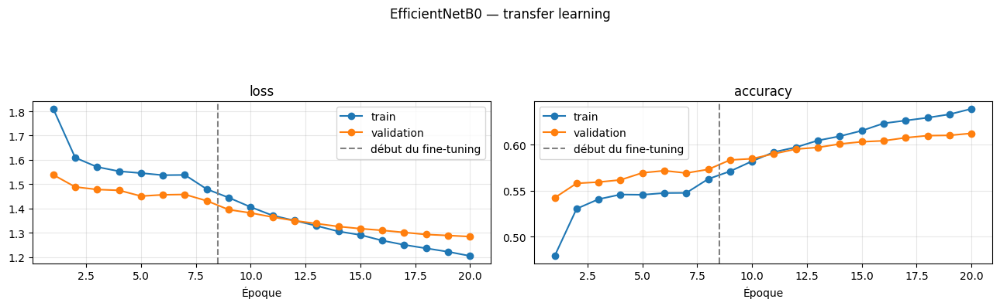

In [9]:
plot_history(RUN_DIR / "training_log.csv", "EfficientNetB0 — transfer learning", phase_boundary=start_epoch)


## Évaluation rapide du modèle fine-tuné


In [10]:
model.load_weights(RUN_DIR / "best_model.keras")
metrics_finetune, y_true, y_pred = evaluate_on_validation(model, val_ds, val_df)
display(pd.DataFrame({
    "feature extraction": metrics_frozen,
    "fine-tuning": metrics_finetune,
}).style.format("{:.4f}"))
print(classification_report(y_true, y_pred, target_names=[str(code) for code in index_to_code]))

save_run_summary(
    RUN_DIR,
    fine_tuning={
        "epochs_run": len(history_finetune.history["loss"]),
        "train_time_min": round(time_finetune_min, 1),
        "unfrozen_layers": len(unfrozen),
        **params_finetune,
        "validation": metrics_finetune,
    },
)


  1/515 ━━━━━━━━━━━━━━━━━━━━ 25:25 3s/step

  2/515 ━━━━━━━━━━━━━━━━━━━━ 1:06 130ms/step

  3/515 ━━━━━━━━━━━━━━━━━━━━ 1:00 119ms/step

  4/515 ━━━━━━━━━━━━━━━━━━━━ 57s 113ms/step 

  5/515 ━━━━━━━━━━━━━━━━━━━━ 1:00 118ms/step

...

515/515 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step

515/515 ━━━━━━━━━━━━━━━━━━━━ 56s 104ms/step


,feature extraction,fine-tuning
accuracy,0.5731,0.6122
top3_accuracy,0.7908,0.8207
f1_weighted,0.5625,0.6049
f1_macro,0.5221,0.5612


              precision    recall  f1-score   support

          10       0.45      0.63      0.53       591
          40       0.53      0.54      0.54       476
          50       0.49      0.38      0.42       320
          60       0.68      0.66      0.67       164
        1140       0.63      0.64      0.64       510
        1160       0.89      0.89      0.89       768
        1180       0.62      0.30      0.41       148
        1280       0.45      0.42      0.44       897
        1281       0.42      0.21      0.28       396
        1300       0.65      0.71      0.68       940
        1301       0.61      0.52      0.56       150
        1302       0.46      0.36      0.41       488
        1320       0.48      0.47      0.47       636
        1560       0.57      0.59      0.58       996
        1920       0.78      0.80      0.79       853
        1940       0.60      0.62      0.61       156
        2060       0.45      0.56      0.50       980
        2220       0.56    

{'label': 'EfficientNetB0 transfer learning',
 'feature_extraction': {'epochs_run': 8,
  'train_time_min': 43.9,
  'params_total': 4084158,
  'params_trainable': 34587,
  'validation': {'accuracy': 0.5730500758725341,
   'top3_accuracy': 0.7908345978755691,
   'f1_weighted': 0.5624748474710015,
   'f1_macro': 0.5221351924711656}},
 'fine_tuning': {'epochs_run': 12,
  'train_time_min': 72.4,
  'unfrozen_layers': 23,
  'params_total': 4084158,
  'params_trainable': 1517947,
  'validation': {'accuracy': 0.6122003034901365,
   'top3_accuracy': 0.8206980273141123,
   'f1_weighted': 0.6048639872235896,
   'f1_macro': 0.561220002090212}}}